# Dataset EDA: human preference comparisons

This is a comparison task: predicting human A/B/tie choices requires correctness,
instruction adherence, style and ambiguity judgments. This notebook describes the
provided labeled table, checks preparation, and identifies testable hypotheses.

Basic schema/counts use the supplied table. Target-association and duplicate-conflict
analyses use training + development, excluding confirmation. All model error analyses
are development-only. The previous confirmation score is historical, not a new test.
Raw text and per-row intermediate files stay under `~/database`; this notebook publishes
aggregate evidence. Three visible test rows cannot establish hidden-test distribution.


In [1]:
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
REPO=next(p for p in [Path.cwd(),Path.cwd().parent,Path.home()/'prj/llm_classification_finetuning'] if (p/'results/eda_002').exists())
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
R=REPO/'results/eda_002'
FIG=ROOT/'reports/eda_002';FIG.mkdir(parents=True,exist_ok=True)
read=lambda name:json.loads((R/name).read_text())
dataset=read('dataset_summary.json');schema=read('schema.json')
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout();plt.savefig(FIG/(name+'.svg'));plt.show()


In [2]:
display(pd.Series({k:dataset[k] for k in ['rows','unique_prompt_groups','prompt_groups_crossing_splits']}))
display(pd.Series(schema['missing_cells'],name='Missing CSV cells'))
display(pd.DataFrame({'train_columns':pd.Series(schema['columns']),'visible_test_columns':pd.Series(schema['test_columns'])}))
print('Visible test rows:',schema['visible_test_rows'])


rows                             57477
unique_prompt_groups             51213
prompt_groups_crossing_splits        0
dtype: int64

id                0
model_a           0
model_b           0
prompt            0
response_a        0
response_b        0
winner_model_a    0
winner_model_b    0
winner_tie        0
Name: Missing CSV cells, dtype: int64

,train_columns,visible_test_columns
0,id,id
1,model_a,prompt
2,model_b,response_a
3,prompt,response_b
4,response_a,NaN
5,response_b,NaN
6,winner_model_a,NaN
7,winner_model_b,NaN
8,winner_tie,NaN


Visible test rows: 3


## Labels and split integrity

The labels are fairly balanced. A constant majority choice is an accuracy baseline;
training frequencies are the appropriate probabilistic baseline. Repeated prompts
are grouped before splitting. Model identities and IDs are not deployed features.


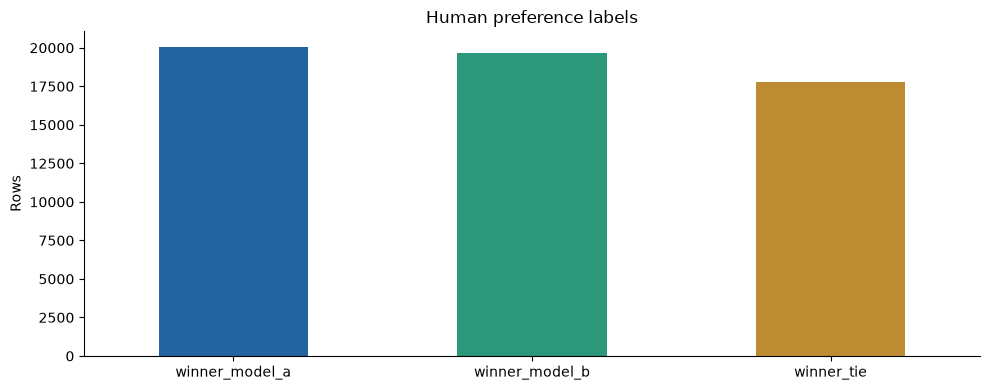

,A,B,Tie
confirmation,0.349112,0.341803,0.309085
dev,0.349112,0.341977,0.308911
train,0.349070,0.341916,0.309014


train           45985
dev              5746
confirmation     5746
Name: Partition sizes, dtype: int64

In [3]:
counts=pd.Series(dataset['global_class_counts'])
counts.plot.bar(rot=0,color=['#2463a1','#2b9979','#bd8b30']);plt.ylabel('Rows');plt.title('Human preference labels');finish('target_counts')
display(pd.DataFrame(dataset['class_proportions_by_split']).T.rename(columns={'0':'A','1':'B','2':'Tie'}))
display(pd.Series(dataset['split_counts'],name='Partition sizes'))
assert dataset['prompt_groups_crossing_splits']==0


## Conversation structure, empty content and repetition

Null turns are preserved as empty text. Turn counts agree across the question and
both responses. Identical questions with different answers are not labeling conflicts.
An exact repeated comparison with different votes is stronger disagreement evidence,
but its small observed subset cannot estimate a global noise floor.


multi_turn                    7539
turn_mismatch                    0
answer_equal_exact             275
answer_equal_whitespace        282
one_answer_empty                25
both_answers_empty              19
one_refusal                   6075
both_refusals                 1667
any_code_answer              12502
wrapper_marker_in_content        3
Name: Structural counts, dtype: int64

prompt          0
response_a    120
response_b    126
Name: Null turn elements, dtype: int64

,distinct,repeated_groups,rows_in_repeated_groups,conflicting_groups,rows_in_conflicting_groups,note
comparison_hash,51680,27,78,4,11,Repeated identical inputs with observed differ...
canonical_comparison_hash,51667,37,101,6,15,Repeated identical inputs with observed differ...


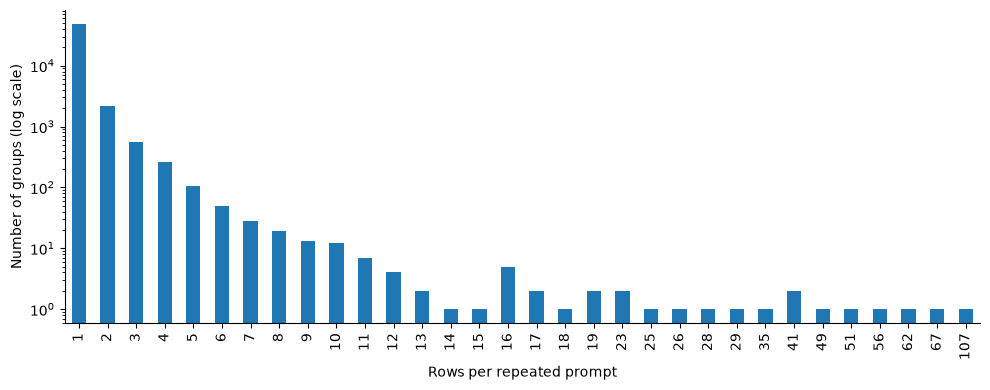

In [4]:
display(pd.Series(dataset['structural_counts'],name='Structural counts'))
display(pd.Series(dataset['null_turn_counts'],name='Null turn elements'))
display(pd.DataFrame(dataset['comparison_duplicates_train_dev']).T)
sizes=pd.Series(dataset['prompt_group_size_distribution'],dtype=float)
sizes.index=sizes.index.astype(int);sizes.sort_index().plot.bar(logy=True)
plt.xlabel('Rows per repeated prompt');plt.ylabel('Number of groups (log scale)');finish('prompt_group_sizes')


## Token lengths and retained content

The exact saved training tokenizer is used. The frozen packer reserves question and
answer fields and retains field beginnings/endings. A larger overall context still
leaves the 256-token question cap unless allocation also changes. Prospective
retention is not measured model quality.


,0.5,0.9,0.95,0.99,1.0
prompt_tokens,22.000,176.000,327.000,1101.000,10429.0
response_a_tokens,233.000,579.400,792.000,1446.240,11812.0
response_b_tokens,235.000,578.000,789.000,1472.240,10510.0
total_content_tokens,527.000,1276.000,1740.000,3368.240,16241.0
prompt_turns,1.000,2.000,2.000,5.000,36.0
answer_word_jaccard,0.237,0.385,0.456,0.778,1.0
answer_length_ratio,1.592,5.430,9.925,39.539,4825.0


,split,packing,any_cut,prompt_cut,answer_cut,mean_content_retained
5,dev,1024_cap256,0.2005,0.0727,0.1657,0.9351
6,dev,2048_cap256,0.0895,0.0687,0.0278,0.9762
7,dev,2048_cap512,0.0541,0.0303,0.0294,0.9847
8,dev,4096_cap256,0.0717,0.0687,0.0044,0.9829
9,dev,4096_cap1024,0.0155,0.0113,0.0054,0.9963


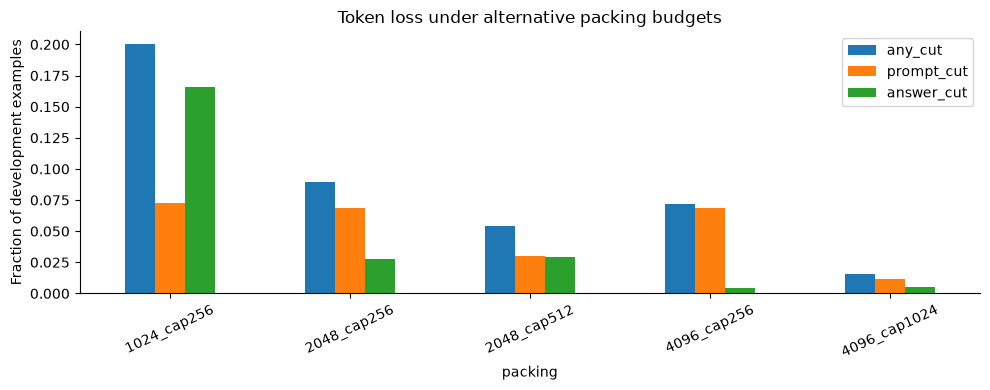

In [5]:
q=pd.DataFrame(dataset['numeric_quantiles']).T
display(q[[c for c in ['0.5','0.9','0.95','0.99','1.0'] if c in q]].round(3))
ret=pd.DataFrame(read('retention.json'))
display(ret[ret.split=='dev'].round(4))
part=ret[ret.split=='dev'].set_index('packing')
part[['any_cut','prompt_cut','answer_cut']].plot.bar(rot=25)
plt.ylabel('Fraction of development examples');plt.title('Token loss under alternative packing budgets');finish('retention_policies')


## Languages and task types

Language labels are estimates from a local detector. Short or code-heavy prompts are
left unknown; the unknown group must not be treated as English or as non-English.
English regex task tags overlap and have false positives (for example, an animal
question mentioning “python”). Topic clusters use existing Qwen embeddings with
centroids fitted on training rows only; keywords are descriptive, not ground truth.


In [6]:
languages=pd.Series(dataset['language_counts_estimated']).sort_values(ascending=False)
display(languages.head(18).to_frame('Rows'))
display(pd.DataFrame(read('dataset_target_associations.json')).query("feature.str.startswith('task_')",engine='python'))
display(pd.DataFrame(dataset['prompt_clusters']))


,Rows
ENGLISH,36170
UNKNOWN_SHORT_OR_CODE,20397
UNKNOWN_LOW_CONFIDENCE,411
CHINESE,86
GERMAN,71
SPANISH,58
FRENCH,43
TAGALOG,32
PORTUGUESE,28
ITALIAN,28


,feature,value,rows,winner_model_a,winner_model_b,winner_tie
13,task_code,False,46895,0.349590,0.341273,0.309137
14,task_code,True,4836,0.344086,0.348222,0.307692
15,task_math,False,50753,0.349713,0.342364,0.307923
16,task_math,True,978,0.315951,0.319018,0.365031
17,task_creative,False,48135,0.346941,0.341893,0.311167
18,task_creative,True,3596,0.377642,0.342325,0.280033
19,task_transformation,False,49482,0.348369,0.342064,0.309567
20,task_transformation,True,2249,0.364606,0.338817,0.296576
21,task_explanation,False,39013,0.345628,0.338374,0.315997
22,task_explanation,True,12718,0.359648,0.352807,0.287545


,cluster,train_rows,keywords
0,0,6307,"[hello, turn, tell, hi, hey, best, life, know,..."
1,1,4234,"[write, joke, tell, poem, turn, tell joke, sto..."
2,2,4225,"[write, turn, code, data, create, company, use..."
3,3,4046,"[apples, sisters, number, 10, step, brothers, ..."
4,4,4635,"[python, code, write, turn, hello, make, test,..."
5,5,2811,"[story, write, character, girl, enable, turn, ..."
6,6,3131,"[turn, does, day, eat, old, cup, best, room, t..."
7,7,3296,"[turn, write, best, good, work, life, like, ma..."
8,8,2809,"[turn, write, did, war, people, world, history..."
9,9,3333,"[explain, turn, does, like, game, theory, list..."


## Preference associations and model metadata

Longer answers and refusal-like wording correlate with human choices, but these are
observational relationships: response quality and task difficulty also vary. Model
identities describe source coverage only; they are absent from the hidden-test input.


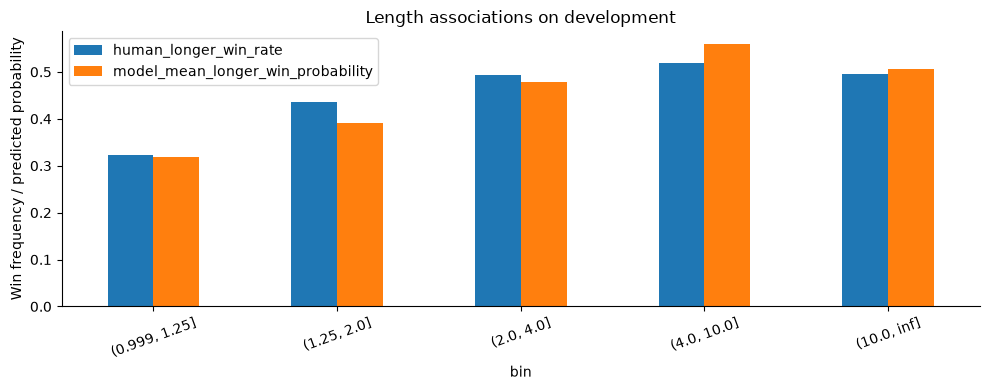

,Appearances in train + dev
gpt-4-1106-preview,6673
gpt-3.5-turbo-0613,6398
gpt-4-0613,5517
claude-2.1,5038
claude-instant-1,3687
gpt-4-0314,3685
claude-1,3573
vicuna-33b,3344
mixtral-8x7b-instruct-v0.1,3202
llama-2-70b-chat,3118


{'diagnostic_only_not_deployable': True,
 'metrics': {'rows': 5746,
  'log_loss': 1.053534261789858,
  'accuracy': 0.43508527671423597,
  'balanced_accuracy': 0.42685967042427175,
  'macro_f1': 0.41432404959277686,
  'brier': 0.6347407079912207},
 'training_model_count': 64,
 'training_pair_count': 1263,
 'development_rows_unseen_pair': 10,
 'note': 'Model identity exists only in the labeled CSV; it is excluded from actual models. Frequencies mix task difficulty and model strength.'}

In [7]:
style=pd.DataFrame(read('style_calibration.json'))
length=style[style.feature=='answer_length_ratio'].set_index('bin')
length[['human_longer_win_rate','model_mean_longer_win_probability']].plot.bar(rot=20)
plt.ylabel('Win frequency / predicted probability');plt.title('Length associations on development');finish('length_preference')
display(pd.Series(read('model_identity_counts.json')).head(20).to_frame('Appearances in train + dev'))
display(read('identity_diagnostic.json'))


## What the dataset does and does not establish

No split overlap or conversation-length mismatch was found. Class imbalance and
rare exact-comparison conflicts are weak explanations of the remaining score gap.
Long and multi-turn comparisons are harder, but causal benefits from packing changes
need model experiments. Language identification and lexical task tags are imperfect.
See notebook 06 for paired model diagnostics, uncertainty and proposed experiments.
